<!-- mccl/notebooks/main.ipynb -->
# MCCL — Notebook principal

Pipeline complet, du chargement des données jusqu'à la boucle incrémentale.

**Sections :**
1. Environnement et imports
2. Chargement des données (zip Load_data)
3. Encodage des labels et splits
4. DataLoaders PyTorch
5. Vérification géométrique (manifolds)
6. Smoke test d'entraînement
7. Boucle incrémentale sur 2 classes
8. Évaluation et matrice d'accuracy
9. Diagnostics géométriques
10. Sauvegarde des résultats

## 1. Environnement et imports

On ajoute `src/` au `PYTHONPATH` pour que `mccl` soit importable, et on fixe les seeds.

In [1]:
# mccl/notebooks/main.ipynb — cellule 1
import sys
from pathlib import Path

# Ajouter src/ au PYTHONPATH
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
SRC = ROOT / "src"
if str(SRC) not in sys.path:
    sys.path.insert(0, str(SRC))

import numpy as np
import torch
import matplotlib.pyplot as plt

from src.utils.seed import set_seed
from src.utils.logging import get_logger

set_seed(0)
log = get_logger("main")

device = "cuda" if torch.cuda.is_available() else "cpu"
print("ROOT   :", ROOT)
print("SRC    :", SRC)
print("device :", device)
print("torch  :", torch.__version__)

ROOT   : c:\Users\hp\Documents\mccl
SRC    : c:\Users\hp\Documents\mccl\src
device : cpu
torch  : 2.14.1+cpu


## 2. Chargement des données

On charge le `dataset.zip` produit par `Load_data.save()`. Il contient un `loader.pkl` (objet `Load_data` sérialisé).

In [2]:
import pickle
import zipfile

# Adapter le chemin
ZIP_PATH = "dataset2.zip"
INTERNAL_NAME = "loader.pkl"

print("Chargement :", ZIP_PATH)

with zipfile.ZipFile(ZIP_PATH, "r") as zf:
    print("Contenu du zip :", zf.namelist())
    with zf.open(INTERNAL_NAME) as f:
        loader = pickle.load(f, encoding="latin1")

Chargement : dataset2.zip
Contenu du zip : ['loader.pkl']


### 2b. Réparation des attributs manquants

Le pickle a été créé avec une ancienne version de `Load_data` : certains attributs (`image_shape_`, `class_mapping_`) peuvent être absents.

In [3]:
# mccl/notebooks/main.ipynb — cellule 3
import copy
import numpy as np

# --- 1. Restaurer data_ depuis original_data_ si nécessaire ---
if loader.data_ is None:
    if getattr(loader, "original_data_", None) is not None:
        loader.data_ = copy.deepcopy(loader.original_data_)
        print("data_ restauré depuis original_data_")
    else:
        raise RuntimeError(
            "Ni data_ ni original_data_ ne sont présents. "
            "Le pickle ne contient pas les images."
        )

real_df = loader.data_
print("DataFrame   :", real_df.shape)
print("Colonnes    :", real_df.columns.tolist())

# --- 2. Réparer image_shape_ ---
if not hasattr(loader, "image_shape_") or loader.image_shape_ is None:
    h, w, c = np.asarray(real_df["Image"].iloc[0]).shape
    loader.image_shape_ = (int(h), int(w), int(c))

# --- 3. Réparer class_mapping_ ---
if not hasattr(loader, "class_mapping_") or not loader.class_mapping_:
    loader.class_mapping_ = {c: i for i, c in enumerate(loader.name_label_)}

# --- 4. original_data_ ---
if not hasattr(loader, "original_data_") or loader.original_data_ is None:
    loader.original_data_ = real_df.copy()

print("Image shape :", loader.image_shape_)
print("Mapping     :", loader.class_mapping_)
print("Répartition :")
print(real_df["Label"].value_counts())

data_ restauré depuis original_data_
DataFrame   : (12138, 2)
Colonnes    : ['Image', 'Label']
Image shape : (240, 240, 3)
Mapping     : {'Canette': 0, 'Organique': 1, 'Plastique': 2, 'Textile': 3, 'Verre': 4}
Répartition :
Label
Verre        2756
Textile      2665
Plastique    2583
Organique    2342
Canette      1792
Name: count, dtype: int64


## 3. Encodage des labels et splits

Split 70/15/15 stratifié par classe. Pas de split par groupe (Load_data ne conserve pas les `source_id`).

In [4]:
# mccl/notebooks/main.ipynb — cellule 4
import numpy as np
from sklearn.model_selection import train_test_split
from src.data.splits import save_splits

# Labels encodés
labels = real_df["Label"].map(loader.class_mapping_).to_numpy(dtype=int)
print("labels :", labels.shape, "| classes :", np.unique(labels))

# Split
idx = np.arange(len(real_df))
tr, tmp = train_test_split(idx, test_size=0.30, stratify=labels, random_state=0)
va, te = train_test_split(tmp, test_size=0.50, stratify=labels[tmp], random_state=0)

print(f"train={len(tr)} | val={len(va)} | test={len(te)}")
print("Counts train :", np.bincount(labels[tr]))
print("Counts val   :", np.bincount(labels[va]))
print("Counts test  :", np.bincount(labels[te]))

# Sauvegarde
save_splits(str(ROOT /"data"/"splits"/"waste5.json"),
            {"train": tr, "val": va, "test": te})
print("Splits sauvegardés.")

labels : (12138,) | classes : [0 1 2 3 4]
train=8496 | val=1821 | test=1821
Counts train : [1254 1639 1808 1866 1929]
Counts val   : [269 351 387 400 414]
Counts test  : [269 352 388 399 413]
Splits sauvegardés.


## 4. DataLoaders PyTorch

Dataset basé sur les images PIL stockées dans `real_df["Image"]`.

In [5]:
# mccl/notebooks/main.ipynb — cellule 5
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms as T

IMAGENET_MEAN = (0.485, 0.456, 0.406)
IMAGENET_STD  = (0.229, 0.224, 0.225)

transform_train = T.Compose([
    T.RandomResizedCrop(224, scale=(0.6, 1.0)),
    T.RandomHorizontalFlip(),
    T.ColorJitter(0.3, 0.3, 0.3, 0.05),
    T.ToTensor(),
    T.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
])

transform_eval = T.Compose([
    T.Resize(256),
    T.CenterCrop(224),
    T.ToTensor(),
    T.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
])


class LoadDataSubset(Dataset):
    def __init__(self, images, labels, indices, transform=None):
        self.images = images
        self.labels = labels
        self.indices = np.asarray(indices)
        self.transform = transform

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, i):
        j = int(self.indices[i])
        img = self.images[j]
        if self.transform is not None:
            img = self.transform(img)
        return img, int(self.labels[j])


images = real_df["Image"].tolist()

ds_train = LoadDataSubset(images, labels, tr, transform_train)
ds_val   = LoadDataSubset(images, labels, va, transform_eval)
ds_test  = LoadDataSubset(images, labels, te, transform_eval)

loader_train = DataLoader(ds_train, batch_size=32, shuffle=True, num_workers=0)
loader_val   = DataLoader(ds_val, batch_size=32, shuffle=False, num_workers=0)
loader_test  = DataLoader(ds_test, batch_size=32, shuffle=False, num_workers=0)

# Vérification
x, y = next(iter(loader_train))
print("Batch x :", x.shape, x.dtype)
print("Batch y :", y.shape, y.dtype)
print("Plage x :", float(x.min()), "→", float(x.max()))

Batch x : torch.Size([32, 3, 224, 224]) torch.float32
Batch y : torch.Size([32]) torch.int64
Plage x : -2.1179039478302 → 2.640000104904175


### 4b. Visualisation d'un batch

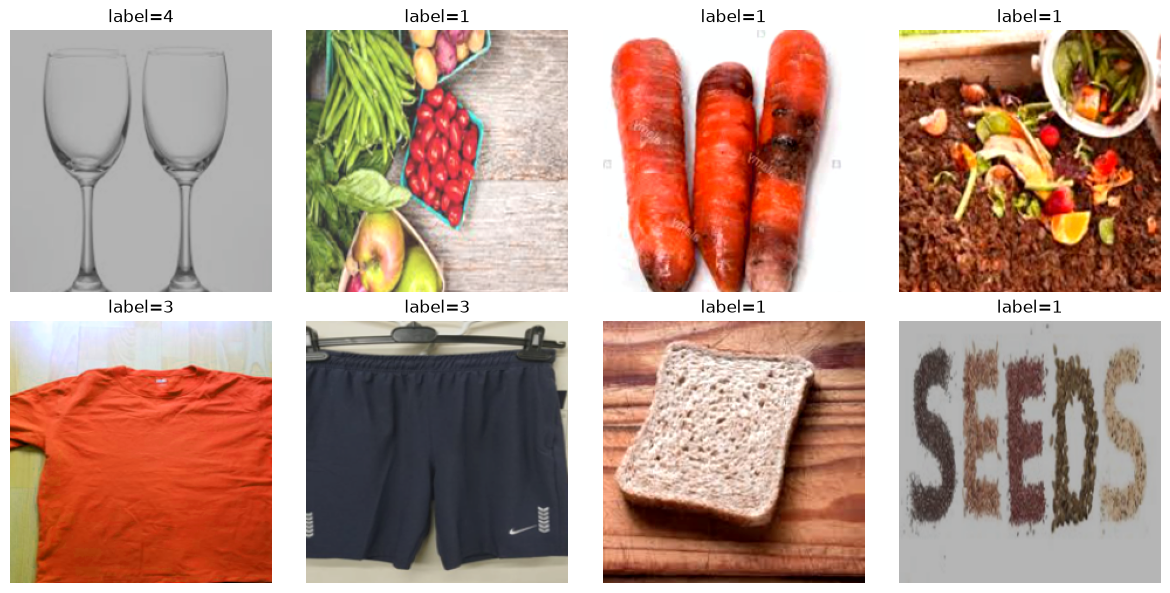

In [6]:

mean = np.array(IMAGENET_MEAN).reshape(3, 1, 1)
std  = np.array(IMAGENET_STD).reshape(3, 1, 1)
x_vis = (x.numpy() * std + mean).clip(0, 1)

fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for i, ax in enumerate(axes.flatten()):
    ax.imshow(np.transpose(x_vis[i], (1, 2, 0)))
    ax.set_title(f"label={y[i].item()}")
    ax.axis("off")
plt.tight_layout()
plt.show()

## 5. Vérification géométrique

Test rapide des manifolds avant de les utiliser dans le modèle.

In [7]:
from src.geometry.manifolds import Euclidean, Hyperbolic, Sphere, ProductManifold
from src.geometry.diagnostics import delta_hyperbolicity, distortion

m = ProductManifold([
    Euclidean(64),
    Hyperbolic(64, curvature=1.0),
    Sphere(64),
])
print("dim produit :", m.dim)

v = torch.randn(5, 192) * 0.3
v[..., 128] = 0.0  # composante sphère
y_man = m.expmap0(v)
v2 = m.logmap0(y_man)
print("Inversion exp/log :", torch.allclose(v, v2, atol=1e-5))
print("Dist symétrique   :", torch.allclose(m.dist(y_man, y_man + 0.1),
                                            m.dist(y_man + 0.1, y_man), atol=1e-6))

pts = m.expmap0(torch.randn(64, 192) * 0.1)
print("δ-hyperbolicité   :", delta_hyperbolicity(pts))
print("Distorsion        :", distortion(pts, pts))

dim produit : 192
Inversion exp/log : True
Dist symétrique   : True
δ-hyperbolicité   : 0.03234255686402321
Distorsion        : 1.0


## 6. Smoke test d'entraînement

On entraîne 1 époque sur les 2 premières classes pour vérifier que la boucle tourne.

In [8]:
import inspect
from src.config import BackboneCfg, ModelCfg

# 1. Voir la valeur par défaut dans la classe
print("Signature BackboneCfg :", inspect.signature(BackboneCfg))

# 2. Voir ce que ModelCfg() produit
cfg = ModelCfg()
print("cfg.backbone.name =", repr(cfg.backbone.name))

# 3. Voir d'où vient le fichier chargé
import src.config
print("Fichier config.py :", src.config.__file__)

Signature BackboneCfg : (name: 'str' = 'dinov2_vits14', num_blocks: 'int' = 10, frozen: 'bool' = True) -> None
cfg.backbone.name = 'dinov2_vits14'
Fichier config.py : c:\Users\hp\Documents\mccl\src\config.py


In [9]:
from src.config import ModelCfg
from src.models.jepa import JepaModel
from src.training.optim import build_optimizer
from src.training.losses import classification_loss

# Configuration
cfg = ModelCfg()
cfg.backbone.frozen = True

# Modèle
model = JepaModel(cfg).to(device)
print("Paramètres :", model.count_parameters())

# Enregistrer 2 classes
model.register_new_classes([0, 1])
print("Classes :", model.classifier.class_ids())

Using cache found in C:\Users\hp/.cache\torch\hub\facebookresearch_dinov2_main
C:\Users\hp/.cache\torch\hub\facebookresearch_dinov2_main\dinov2\layers\swiglu_ffn.py:51: UserWarning: xFormers is not available (SwiGLU)
  warnings.warn("xFormers is not available (SwiGLU)")
C:\Users\hp/.cache\torch\hub\facebookresearch_dinov2_main\dinov2\layers\attention.py:33: UserWarning: xFormers is not available (Attention)
  warnings.warn("xFormers is not available (Attention)")
C:\Users\hp/.cache\torch\hub\facebookresearch_dinov2_main\dinov2\layers\block.py:40: UserWarning: xFormers is not available (Block)
  warnings.warn("xFormers is not available (Block)")


11:10:43 | INFO    | src.models.backbone | Backbone tronqué : 10 blocs sur 12
11:10:43 | INFO    | src.models.backbone | Backbone gelé
Paramètres : {'total': 18877440, 'trainable': 371328}
Classes : [0, 1]


  0%|          | 0/4 [00:00<?, ?it/s]C:\Users\hp\AppData\Local\Temp\ipykernel_9152\3615153991.py:22: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\torch\csrc\autograd\generated\python_variable_methods.cpp:821.)
  losses.append(float(loss))
100%|██████████| 4/4 [19:42<00:00, 295.65s/it]


Loss initiale : 0.6866
Loss finale   : 0.0085


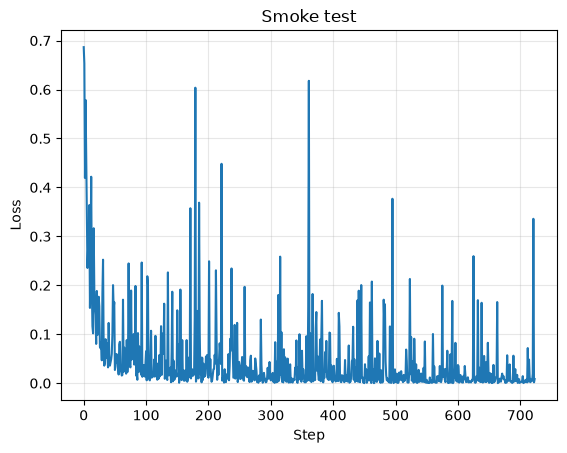

In [10]:
# mccl/notebooks/main.ipynb — cellule 9
# Filtrer pour 2 classes
from tqdm import tqdm
mask_train = np.isin(labels[tr], [0, 1])
tr_2 = tr[mask_train]

ds_2 = LoadDataSubset(images, labels, tr_2, transform_train)
loader_2 = DataLoader(ds_2, batch_size=16, shuffle=True, num_workers=0)

# Optimiseur
opt = build_optimizer(model, lr=1e-3)

# Boucle simple
model.train()
losses = []
for epoch in tqdm(range(4)):
    for xb, yb in tqdm(loader_2, desc=f"Epoch {epoch + 1}"):
        xb, yb = xb.to(device), yb.to(device)
        out = model(xb)
        loss = classification_loss(out.logits, yb)
        opt.zero_grad(); loss.backward(); opt.step()
        losses.append(float(loss))

print(f"Loss initiale : {losses[0]:.4f}")
print(f"Loss finale   : {losses[-1]:.4f}")

plt.plot(losses)
plt.xlabel("Step"); plt.ylabel("Loss")
plt.title("Smoke test")
plt.grid(alpha=0.3); plt.show()

In [11]:
model.eval()
correct = 0
total = 0
with torch.no_grad():
    for xb, yb in loader_2:
        xb, yb = xb.to(device), yb.to(device)
        out = model(xb)
        pred = out.logits.argmax(dim=-1)
        correct += (pred == yb).sum().item()
        total += yb.size(0)

print(f"Accuracy train (2 classes) : {correct / total:.4f}")

KeyboardInterrupt: 

In [12]:
@torch.no_grad()
def eval_loader(model, loader, device):
    model.eval()
    correct, total = 0, 0
    for xb, yb in loader:
        xb, yb = xb.to(device), yb.to(device)
        out = model(xb)
        pred = out.logits.argmax(dim=-1)
        correct += (pred == yb).sum().item()
        total += yb.size(0)
    return correct / max(total, 1)


# Filtrer val et test sur les 2 classes
mask_val = np.isin(labels[va], [0, 1])
mask_test = np.isin(labels[te], [0, 1])

ds_val_2 = LoadDataSubset(images, labels, va[mask_val], transform_eval)
ds_test_2 = LoadDataSubset(images, labels, te[mask_test], transform_eval)
loader_val_2 = DataLoader(ds_val_2, batch_size=32, shuffle=False)
loader_test_2 = DataLoader(ds_test_2, batch_size=32, shuffle=False)

acc_train = eval_loader(model, loader_2, device)
acc_val = eval_loader(model, loader_val_2, device)
acc_test = eval_loader(model, loader_test_2, device)

print(f"Accuracy train : {acc_train:.4f}")
print(f"Accuracy val   : {acc_val:.4f}")
print(f"Accuracy test  : {acc_test:.4f}")

Accuracy train : 0.9955
Accuracy val   : 0.9855
Accuracy test  : 0.9936


In [13]:
# Distance moyenne intra-classe vs inter-classe
@torch.no_grad()
def cluster_separation(model, loader):
    emb, ys = [], []
    for xb, yb in loader:
        xb = xb.to(device)
        out = model(xb)
        emb.append(out.global_embed.cpu())
        ys.append(yb)
    emb = torch.cat(emb, 0)
    ys = torch.cat(ys, 0)

    intra, inter = [], []
    for c in ys.unique():
        m_c = emb[ys == c]
        # Distance moyenne intra-classe
        d_intra = torch.cdist(m_c, m_c).mean().item()
        intra.append(d_intra)
        # Distance moyenne vers les autres classes
        m_o = emb[ys != c]
        d_inter = torch.cdist(m_c, m_o).mean().item()
        inter.append(d_inter)

    return float(np.mean(intra)), float(np.mean(inter))

d_intra, d_inter = cluster_separation(model, loader_val_2)
print(f"Distance intra-classe : {d_intra:.4f}")
print(f"Distance inter-classe : {d_inter:.4f}")
print(f"Ratio inter/intra     : {d_inter / d_intra:.2f}")

Distance intra-classe : 8.1779
Distance inter-classe : 25.9838
Ratio inter/intra     : 3.18


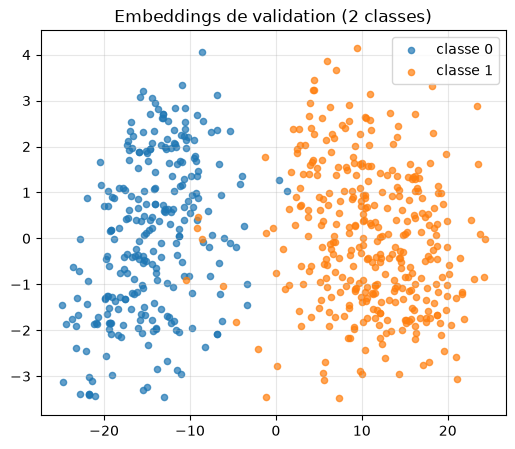

In [14]:
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

@torch.no_grad()
def get_embeddings(model, loader):
    model.eval()
    feats, ys = [], []
    for xb, yb in loader:
        xb = xb.to(device)
        out = model(xb)
        feats.append(out.global_embed.cpu())
        ys.append(yb)
    return torch.cat(feats, 0), torch.cat(ys, 0)

emb, y_emb = get_embeddings(model, loader_val_2)
emb_2d = PCA(n_components=2).fit_transform(emb.numpy())

plt.figure(figsize=(6, 5))
for c in y_emb.unique():
    m = (y_emb == c).numpy()
    plt.scatter(emb_2d[m, 0], emb_2d[m, 1], s=20, alpha=0.7, label=f"classe {int(c)}")
plt.legend()
plt.title("Embeddings de validation (2 classes)")
plt.grid(alpha=0.3)
plt.show()

In [15]:
with torch.no_grad():
    protos = model.classifier.prototype_tensor()
    d = model.manifold.dist(protos[0:1], protos[1:2])
    print("Distance entre les 2 prototypes :", float(d))

Distance entre les 2 prototypes : 0.5357838273048401


## 7. Boucle incrémentale sur 2 classes

On utilise `TaskStream` pour itérer sur les tâches. Ordre naturel `[0,1,2,3,4]` : tâche 0 = {0,1}, puis +1 classe par tâche.

In [12]:
# mccl/notebooks/main.ipynb — cellule 10
from src.data.incremental import TaskStream

order = [0, 1, 2, 3, 4]
stream = TaskStream(labels, order=order,
                    train_idx=tr, val_idx=va, test_idx=te)

for task in stream:
    print(f"tâche {task.index} | classes={task.classes} | "
          f"seen={task.seen_classes} | "
          f"n_train={len(task.train_idx)} | n_test={len(task.test_idx)}")

tâche 0 | classes=[0, 1] | seen=[0, 1] | n_train=2893 | n_test=621
tâche 1 | classes=[2] | seen=[0, 1, 2] | n_train=1808 | n_test=1009
tâche 2 | classes=[3] | seen=[0, 1, 2, 3] | n_train=1866 | n_test=1408
tâche 3 | classes=[4] | seen=[0, 1, 2, 3, 4] | n_train=1929 | n_test=1821


## 8. Boucle incrémentale complète

Pour chaque tâche : entraîner, évaluer sur les classes vues, remplir la matrice d'accuracy.

In [10]:

import numpy as np
import torch
from tqdm.auto import tqdm
from torch.utils.data import DataLoader

from src.config import ModelCfg
from src.models.jepa import JepaModel
from src.training.optim import build_optimizer
from src.training.losses import classification_loss
from src.training.trainer import train_one_task
from src.evaluation.metrics import per_class_accuracy
from src.continual.strategies import build_strategy
from src.geometry.diagnostics import geometry_report
from src.utils.viz import plot_accuracy_matrix, plot_dashboard



In [ ]:

@torch.no_grad()
def eval_per_class(model, indices, n_classes_max=5):
    model.eval()
    ds = LoadDataSubset(images, labels, indices, transform_eval)
    dl = DataLoader(ds, batch_size=32, shuffle=False, num_workers=0)
    all_logits, all_y = [], []
    for xb, yb in dl:
        xb = xb.to(device)
        out = model(xb)
        if out.logits is None:
            continue
        all_logits.append(out.logits.cpu())
        all_y.append(yb)
    if not all_logits:
        return {}
    logits = torch.cat(all_logits, 0)
    y_all = torch.cat(all_y, 0)
    pc = per_class_accuracy(logits, y_all, n_classes_max)
    return {c: float(pc[c]) for c in range(n_classes_max)
            if not np.isnan(pc[c])}


@torch.no_grad()
def collect_embeddings(model, indices, n_max=512):
    """Extrait les embeddings globaux sur un sous-ensemble."""
    model.eval()
    subset = indices[:n_max]
    ds = LoadDataSubset(images, labels, subset, transform_eval)
    dl = DataLoader(ds, batch_size=32, shuffle=False, num_workers=0)
    feats = []
    for xb, _ in dl:
        xb = xb.to(device)
        out = model(xb)
        if out.global_embed is not None:
            feats.append(out.global_embed.cpu())
    if not feats:
        return None
    return torch.cat(feats, 0)


def run_incremental(strategy_name: str, n_epochs: int = 2, batch_size: int = 16):
    model_incr = JepaModel(cfg).to(device)
    opt = build_optimizer(model_incr, lr=1e-3)

    # Stratégie
    if strategy_name == "replay":
        strategy = build_strategy("replay", capacity=512)
    elif strategy_name == "ewc":
        strategy = build_strategy("ewc", lam=1e4, n_samples=256)
        strategy.attach_model(model_incr)
    elif strategy_name == "dual_memory":
        strategy = build_strategy("dual_memory")
    else:
        strategy = build_strategy(strategy_name)

    T = len(order) - 1                          # 4 tâches
    n_classes = len(loader.name_label_)         # 5 classes
    acc_matrix = np.full((T, n_classes), np.nan)  # ← (4, 5) au lieu de (4, 4)

    history_all = []
    log_states = []
    geometry_history = []

    for task in tqdm(stream, desc=f"Stream ({strategy_name})", position=0):
        model_incr.register_new_classes(task.classes)
        strategy.begin_task(task)
        print(f"\n=== Tâche {task.index} | classes={task.classes} "
              f"| strategy={strategy_name} ===")

        if strategy_name == "joint":
            train_idx = tr[np.isin(labels[tr], task.seen_classes)]
        else:
            train_idx = task.train_idx

        ds_t = LoadDataSubset(images, labels, train_idx, transform_train)
        dl_t = DataLoader(ds_t, batch_size=batch_size, shuffle=True, num_workers=0)

        def loss_fn(model, batch, out):
            xb, yb = batch
            yb = yb.to(device)
            loss = classification_loss(out.logits, yb)
            replay = strategy.sample_replay(xb.size(0))
            if replay is not None:
                xr, yr = replay
                out_r = model(xr.to(device))
                loss = loss + classification_loss(out_r.logits, yr.to(device))
            pen = strategy.penalty()
            if pen.requires_grad or pen.item() > 0:
                loss = loss + pen
            return loss

        def on_step(state, batch):
            xb, yb = batch
            with torch.no_grad():
                out = model_incr(xb.to(device))
            strategy.observe((xb.detach().cpu(), yb.detach().cpu()), out=out)

        state = train_one_task(
            model=model_incr, train_loader=dl_t, optimizer=opt,
            n_epochs=n_epochs, loss_fn=loss_fn, device=device,
            max_grad_norm=1.0, on_step=on_step,
            task_idx=task.index, verbose=True,
        )
        history_all.append({"task": task.index, "history": state.history})

        strategy.end_task(task, train_loader=dl_t)

        per_class = eval_per_class(model_incr, task.test_idx, n_classes_max=n_classes)
        print(f"    accuracy : { {k: round(v, 3) for k, v in per_class.items()} }")

        # ← CORRECTION : chaque classe vue a sa colonne
        for j, c in enumerate(task.seen_classes):
            if c in per_class:
                acc_matrix[task.index, j] = per_class[c]

        # Diagnostics géométriques
        emb = collect_embeddings(model_incr, task.test_idx, n_max=256)
        if emb is not None and emb.numel() > 0:
            diag = geometry_report(
                emb, manifold=model_incr.manifold,
                n_quadruples=256, n_samples_curvature=128,
            )
            diag["task"] = task.index
            geometry_history.append(diag)
        else:
            geometry_history.append({"task": task.index})

        log_states.append({"task": task.index, "state": strategy.state()})

    return acc_matrix, history_all, log_states, geometry_history


# ---------------------------------------------------------------------------
# Exécution
# ---------------------------------------------------------------------------
STRATEGY = "dual_memory"

acc_matrix, history_all, log_states, geometry_history = run_incremental(
    strategy_name=STRATEGY,
    n_epochs=2,
    batch_size=16,
)

print("\nMatrice d'accuracy :")
print(np.round(acc_matrix, 3))

print("\nDiagnostics géométriques par tâche :")
for d in geometry_history:
    print(f"  Tâche {d.get('task', '?')} :")
    for k, v in d.items():
        if k != "task" and isinstance(v, (int, float)):
            print(f"    {k:28s} = {v:.4f}")

Using cache found in C:\Users\hp/.cache\torch\hub\facebookresearch_dinov2_main


11:11:57 | INFO    | src.models.backbone | Backbone tronqué : 10 blocs sur 12
11:11:57 | INFO    | src.models.backbone | Backbone gelé


Stream (dual_memory):   0%|          | 0/4 [00:00<?, ?it/s]

11:11:57 | INFO    | src.continual.strategies | [DualMemory] début tâche 0 | classes=[0, 1]

=== Tâche 0 | classes=[0, 1] | strategy=dual_memory ===


[Tâche 0] époques:   0%|          | 0/2 [00:00<?, ?it/s]

  epoch 1/2:   0%|          | 0/181 [00:00<?, ?it/s]

In [25]:
# mccl/src/mccl/utils/viz.py
"""Visualisations publication-ready pour MCCL.

Style inspiré des figures de NeurIPS/ICML :
- palette colorblind-safe (Okabe-Ito étendue) ;
- typographie unique (DejaVu Sans, poids cohérents) ;
- grilles légères, spines fines ;
- annotations contextuelles (valeurs, deltas, flèches) ;
- export SVG/PDF/PNG 300 dpi.
"""
from __future__ import annotations

from pathlib import Path
from typing import Dict, List, Optional, Sequence, Tuple

import numpy as np


# ---------------------------------------------------------------------------
# Palette colorblind-safe (Wong / Okabe-Ito étendue)
# ---------------------------------------------------------------------------
PALETTE = {
    "finetune":    "#D55E00",   # vermillon
    "joint":       "#009E73",   # vert
    "replay":      "#0072B2",   # bleu
    "ewc":         "#E69F00",   # orange
    "dual_memory": "#CC79A7",   # rose
    "euclid":      "#56B4E9",   # bleu ciel
    "hyper_only":  "#8E44AD",   # violet
    "sphere_only": "#16A085",   # teal
    "mixed":       "#F0E442",   # jaune (rare)
}

CYCLE = [
    "#0072B2", "#D55E00", "#009E73", "#E69F00",
    "#CC79A7", "#56B4E9", "#8E44AD", "#16A085",
]

NEUTRAL = {
    "bg":      "#FFFFFF",
    "panel":   "#FAFBFC",
    "grid":    "#E4E8EC",
    "text":    "#1A1A1A",
    "muted":   "#6B7280",
    "border":  "#D1D5DB",
    "accent":  "#DC2626",
}


def _color(name: str, idx: int = 0) -> str:
    return PALETTE.get(name, CYCLE[idx % len(CYCLE)])


# ---------------------------------------------------------------------------
# Style global
# ---------------------------------------------------------------------------
_STYLE_APPLIED = False


def _apply_style():
    """Applique un style scientifique une seule fois."""
    global _STYLE_APPLIED
    if _STYLE_APPLIED:
        return
    import matplotlib.pyplot as plt
    plt.rcParams.update({
        "figure.facecolor": NEUTRAL["bg"],
        "axes.facecolor": NEUTRAL["panel"],
        "axes.edgecolor": NEUTRAL["border"],
        "axes.linewidth": 0.8,
        "axes.labelcolor": NEUTRAL["text"],
        "axes.labelsize": 10,
        "axes.labelweight": "medium",
        "axes.titlesize": 11,
        "axes.titleweight": "semibold",
        "axes.titlepad": 10,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "grid.color": NEUTRAL["grid"],
        "grid.linewidth": 0.6,
        "grid.linestyle": "-",
        "grid.alpha": 0.9,
        "xtick.color": NEUTRAL["muted"],
        "ytick.color": NEUTRAL["muted"],
        "xtick.labelsize": 9,
        "ytick.labelsize": 9,
        "xtick.direction": "out",
        "ytick.direction": "out",
        "xtick.major.size": 3,
        "ytick.major.size": 3,
        "legend.frameon": False,
        "legend.fontsize": 9,
        "legend.title_fontsize": 9,
        "legend.handlelength": 1.5,
        "font.family": "DejaVu Sans",
        "font.size": 10,
        "lines.linewidth": 2.0,
        "lines.markersize": 5,
        "patch.linewidth": 0.6,
        "savefig.facecolor": NEUTRAL["bg"],
        "savefig.bbox": "tight",
        "savefig.pad_inches": 0.15,
    })
    _STYLE_APPLIED = True


def _save(fig, path: Optional[str], dpi: int = 300):
    """Sauvegarde en PNG 300 dpi + SVG si demandé."""
    if not path:
        return
    p = Path(path)
    p.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(p, dpi=dpi)
    if p.suffix.lower() == ".png":
        fig.savefig(p.with_suffix(".svg"))


def _get_cmap(name: str):
    import matplotlib.pyplot as plt
    return plt.get_cmap(name).copy()


def _finish(fig, title: Optional[str] = None):
    """Sous-titre global + tight_layout."""
    if title:
        fig.suptitle(title, fontsize=13, fontweight="bold",
                     color=NEUTRAL["text"], y=1.02)
    fig.tight_layout()
    import matplotlib.pyplot as plt
    plt.show()


# ---------------------------------------------------------------------------
# 1. Matrice d'accuracy
# ---------------------------------------------------------------------------
def plot_accuracy_matrix(
    acc_matrix: np.ndarray,
    class_names: Optional[List[str]] = None,
    title: str = "Accuracy par tâche et par classe",
    save_path: Optional[str] = None,
    cmap: str = "Blues",
    figsize: Optional[Tuple] = None,
    annotate: bool = True,
    highlight_diagonal: bool = True,
):
    """Matrice d'accuracy avec annotations et style publication."""
    import matplotlib.pyplot as plt
    _apply_style()

    T, C = acc_matrix.shape
    if figsize is None:
        figsize = (max(5.5, 0.9 * C + 3), max(3.8, 0.6 * T + 1.5))

    fig, ax = plt.subplots(figsize=figsize)
    masked = np.ma.masked_invalid(acc_matrix)
    cm = _get_cmap(cmap)
    cm.set_bad(color=NEUTRAL["grid"])

    im = ax.imshow(masked, cmap=cm, vmin=0.0, vmax=1.0, aspect="auto")

    # Lignes de séparation entre tâches (fines, blanches)
    for i in range(1, T):
        ax.axhline(i - 0.5, color="white", linewidth=2.5)
    for j in range(1, C):
        ax.axvline(j - 0.5, color="white", linewidth=2.5)

    # Annotations
    if annotate:
        for i in range(T):
            for j in range(C):
                v = acc_matrix[i, j]
                if np.isnan(v):
                    continue
                color = "white" if v > 0.55 else NEUTRAL["text"]
                weight = "bold" if (highlight_diagonal and i == j) else "normal"
                ax.text(j, i, f"{v:.2f}", ha="center", va="center",
                        color=color, fontsize=8.5, fontweight=weight)

    # Ticks
    ax.set_xticks(range(C))
    if class_names:
        ax.set_xticklabels(class_names, rotation=35, ha="right")
    else:
        ax.set_xticklabels([f"C{j}" for j in range(C)])
    ax.set_yticks(range(T))
    ax.set_yticklabels([f"Après T{i}" for i in range(T)])

    ax.set_xlabel("Classe évaluée")
    ax.set_ylabel("Après entraînement de")
    ax.set_title(title, loc="left", pad=12)
    ax.grid(False)

    # Colorbar élégante
    cbar = fig.colorbar(im, ax=ax, fraction=0.03, pad=0.02)
    cbar.set_label("Accuracy", fontsize=9)
    cbar.outline.set_visible(False)
    cbar.ax.tick_params(labelsize=8)

    fig.tight_layout()
    _save(fig, save_path)
    plt.show()


# ---------------------------------------------------------------------------
# 2. Courbes d'apprentissage
# ---------------------------------------------------------------------------
def plot_learning_curves(
    history: List[Dict],
    title: str = "Courbes d'apprentissage",
    save_path: Optional[str] = None,
    show: bool = True,
):
    """Loss et accuracy par époque, style publication."""
    import matplotlib.pyplot as plt
    _apply_style()

    if not history:
        return

    epochs = [h.get("epoch", i) + 1 for i, h in enumerate(history)]
    keys = [k for k in history[0].keys() if k != "epoch"]

    n = len(keys)
    fig, axes = plt.subplots(1, n, figsize=(4.2 * n, 3.4))
    if n == 1:
        axes = [axes]

    for ax, k in zip(axes, keys):
        vals = np.array([h.get(k, np.nan) for h in history], dtype=float)
        is_loss = "loss" in k.lower()
        color = PALETTE["finetune"] if is_loss else PALETTE["joint"]

        # Ligne principale
        ax.plot(epochs, vals, color=color, linewidth=2.2,
                marker="o", markersize=5, markerfacecolor="white",
                markeredgewidth=1.8, zorder=3)

        # Aire douce
        ax.fill_between(epochs, vals, alpha=0.12, color=color, zorder=2)

        # Annoter première et dernière valeur
        if len(vals) >= 2:
            ax.annotate(f"{vals[0]:.3f}", xy=(epochs[0], vals[0]),
                        xytext=(6, 6), textcoords="offset points",
                        fontsize=8.5, color=NEUTRAL["muted"])
            ax.annotate(f"{vals[-1]:.3f}", xy=(epochs[-1], vals[-1]),
                        xytext=(-30, 8), textcoords="offset points",
                        fontsize=9, fontweight="bold", color=color)

        ax.set_xlabel("Époque")
        ax.set_ylabel(k.replace("_", " ").title())
        ax.set_title(k.replace("_", " ").title(), loc="left")
        ax.set_xticks(epochs)

    fig.suptitle(title, fontsize=13, fontweight="bold",
                 color=NEUTRAL["text"], y=1.02)
    fig.tight_layout()
    _save(fig, save_path)
    if show:
        plt.show()


# ---------------------------------------------------------------------------
# 3. Comparaison de stratégies (bar chart)
# ---------------------------------------------------------------------------
def plot_strategy_comparison(
    results: Dict[str, np.ndarray],
    metric: str = "avg_acc",
    title: Optional[str] = None,
    save_path: Optional[str] = None,
    class_names: Optional[List[str]] = None,
):
    """Comparaison de plusieurs stratégies."""
    import matplotlib.pyplot as plt
    _apply_style()

    names = list(results.keys())
    colors = [_color(n, i) for i, n in enumerate(names)]

    metrics = {n: {
        "avg_acc": float(np.nanmean(results[n][-1])),
        "forgetting": _compute_forgetting(results[n]),
        "bwt": _compute_bwt(results[n]),
    } for n in names}

    if metric == "per_class":
        fig, ax = plt.subplots(
            figsize=(max(7, 1.4 * len(class_names or [])), 4.2))
        last_row = {n: results[n][-1] for n in names}
        n_classes = len(next(iter(last_row.values())))
        x = np.arange(n_classes)
        width = 0.8 / len(names)
        for i, name in enumerate(names):
            vals = [last_row[name][c] if not np.isnan(last_row[name][c])
                    else 0 for c in range(n_classes)]
            bars = ax.bar(x + i * width - 0.4 + width / 2, vals,
                          width=width, label=name, color=colors[i],
                          edgecolor="white", linewidth=1.2)
        ax.set_xticks(x)
        ax.set_xticklabels(class_names or [f"C{c}" for c in range(n_classes)],
                           rotation=25, ha="right")
        ax.set_ylabel("Accuracy finale")
        ax.set_ylim(0, 1.08)
        ax.legend(loc="upper right", ncol=2, columnspacing=1.2)
        ax.set_title(title or "Accuracy finale par classe", loc="left")
    else:
        fig, ax = plt.subplots(figsize=(6.5, 4.2))
        vals = [metrics[n][metric] for n in names]
        bars = ax.bar(names, vals, color=colors, edgecolor="white",
                      linewidth=1.5, width=0.65)

        # Annotations
        ymax = max(vals) if vals else 1.0
        for bar, v in zip(bars, vals):
            ax.text(bar.get_x() + bar.get_width() / 2,
                    bar.get_height() + 0.02 * ymax,
                    f"{v:.3f}", ha="center", va="bottom",
                    fontsize=10, fontweight="bold",
                    color=NEUTRAL["text"])

        ax.set_ylabel(metric.replace("_", " ").title())
        if metric in ("avg_acc", "bwt"):
            ax.set_ylim(0, 1.08)
        ax.set_title(title or f"{metric.replace('_', ' ').title()} par stratégie",
                     loc="left")
        ax.grid(axis="y")
        ax.grid(axis="x", visible=False)

    fig.tight_layout()
    _save(fig, save_path)
    plt.show()


# ---------------------------------------------------------------------------
# 4. Courbes de rétention
# ---------------------------------------------------------------------------
def plot_retention_curves(
    results: Dict[str, np.ndarray],
    class_names: Optional[List[str]] = None,
    save_path: Optional[str] = None,
):
    """Un panneau par stratégie, une courbe par classe."""
    import matplotlib.pyplot as plt
    _apply_style()

    names = list(results.keys())
    n = len(names)
    fig, axes = plt.subplots(1, n, figsize=(4.2 * n, 3.8), sharey=True)
    if n == 1:
        axes = [axes]

    for ax, strat in zip(axes, names):
        mat = results[strat]
        T, C = mat.shape
        x = np.arange(T)
        for c in range(C):
            col = mat[:, c]
            valid = ~np.isnan(col)
            if valid.sum() == 0:
                continue
            color = CYCLE[c % len(CYCLE)]
            label = class_names[c] if class_names else f"classe {c}"
            ax.plot(x[valid], col[valid], color=color, linewidth=2,
                    marker="o", markersize=4.5, markerfacecolor="white",
                    markeredgewidth=1.5, label=label)

        ax.set_title(strat, loc="left")
        ax.set_xlabel("Après tâche")
        ax.set_xticks(x)
        ax.set_xticklabels([f"T{i}" for i in x])
        ax.set_ylim(0, 1.05)
        if ax is axes[0]:
            ax.set_ylabel("Accuracy")
        ax.legend(fontsize=7.5, loc="lower left", ncol=2,
                  columnspacing=1.0, handlelength=1.2)

    fig.suptitle("Rétention par classe au fil des tâches",
                 fontsize=13, fontweight="bold",
                 color=NEUTRAL["text"], y=1.02)
    fig.tight_layout()
    _save(fig, save_path)
    plt.show()


# ---------------------------------------------------------------------------
# 5. Radar multi-critères
# ---------------------------------------------------------------------------
def plot_radar(
    results: Dict[str, np.ndarray],
    criteria: Optional[List[str]] = None,
    save_path: Optional[str] = None,
):
    """Radar comparatif avec remplissage doux."""
    import matplotlib.pyplot as plt
    _apply_style()

    names = list(results.keys())
    per_strat = {}
    for name, mat in results.items():
        avg = float(np.nanmean(mat[-1]))
        forget = _compute_forgetting(mat)
        bwt = _compute_bwt(mat)
        per_strat[name] = {
            "Avg acc": avg,
            "1 − forgetting": max(0.0, 1.0 - forget),
            "Backward transfer": max(0.0, min(1.0, (bwt + 0.5) / 1.0)),
            "Stability": max(0.0, min(1.0, 1.0 - forget)),
            "Plasticity": avg,
        }

    if criteria is None:
        criteria = list(next(iter(per_strat.values())).keys())

    angles = np.linspace(0, 2 * np.pi, len(criteria), endpoint=False).tolist()
    angles += angles[:1]

    fig, ax = plt.subplots(figsize=(6.5, 6.5),
                           subplot_kw=dict(polar=True))
    ax.set_facecolor(NEUTRAL["panel"])

    for i, name in enumerate(names):
        vals = [per_strat[name][c] for c in criteria]
        vals += vals[:1]
        color = _color(name, i)
        ax.plot(angles, vals, linewidth=2.2, color=color, label=name)
        ax.fill(angles, vals, color=color, alpha=0.12)

    ax.set_xticks(angles[:-1])
    ax.set_xticklabels(criteria, fontsize=9.5)
    ax.set_ylim(0, 1.05)
    ax.set_yticks([0.2, 0.4, 0.6, 0.8, 1.0])
    ax.set_yticklabels(["0.2", "0.4", "0.6", "0.8", "1.0"], fontsize=8,
                       color=NEUTRAL["muted"])
    ax.grid(color=NEUTRAL["grid"], linewidth=0.6)
    ax.spines["polar"].set_color(NEUTRAL["border"])
    ax.legend(loc="upper right", bbox_to_anchor=(1.25, 1.12),
              frameon=False, fontsize=9)
    ax.set_title("Comparaison multi-critères",
                 fontsize=13, fontweight="bold", pad=28,
                 color=NEUTRAL["text"])

    fig.tight_layout()
    _save(fig, save_path)
    plt.show()


# ---------------------------------------------------------------------------
# 6. Diagnostics géométriques
# ---------------------------------------------------------------------------
def plot_geometry_diagnostics(
    diagnostics_per_task: List[Dict],
    title: str = "Diagnostics géométriques par tâche",
    save_path: Optional[str] = None,
):
    """Grille de courbes pour chaque métrique géométrique."""
    import matplotlib.pyplot as plt
    _apply_style()

    if not diagnostics_per_task:
        return

    keys = [k for k in diagnostics_per_task[0].keys() if k != "task"]
    n = len(keys)
    cols = min(3, n)
    rows = (n + cols - 1) // cols

    fig, axes = plt.subplots(rows, cols, figsize=(4.0 * cols, 3.2 * rows))
    axes = axes.flatten() if n > 1 else [axes]

    tasks = [d.get("task", i) for i, d in enumerate(diagnostics_per_task)]

    for ax, k in zip(axes, keys):
        vals = [d.get(k, np.nan) for d in diagnostics_per_task]
        color = PALETTE["replay"]
        ax.plot(tasks, vals, color=color, linewidth=2.2,
                marker="o", markersize=6, markerfacecolor="white",
                markeredgewidth=1.8, zorder=3)
        ax.fill_between(tasks, vals, alpha=0.12, color=color, zorder=2)
        ax.set_xlabel("Tâche")
        ax.set_ylabel(k.replace("_", " ").title())
        ax.set_title(k.replace("_", " ").title(), loc="left")
        ax.set_xticks(tasks)

        if vals and not np.isnan(vals[-1]):
            ax.annotate(f"{vals[-1]:.3f}",
                        xy=(tasks[-1], vals[-1]),
                        xytext=(-30, 8), textcoords="offset points",
                        fontsize=9, fontweight="bold", color=color)

    for ax in axes[n:]:
        ax.axis("off")

    fig.suptitle(title, fontsize=13, fontweight="bold",
                 color=NEUTRAL["text"], y=1.02)
    fig.tight_layout()
    _save(fig, save_path)
    plt.show()


# ---------------------------------------------------------------------------
# 7. Embeddings 2D
# ---------------------------------------------------------------------------
def plot_embeddings_2d(
    embeddings: np.ndarray,
    labels: np.ndarray,
    method: str = "tsne",
    class_names: Optional[List[str]] = None,
    title: str = "Projection 2D des embeddings",
    save_path: Optional[str] = None,
):
    """Scatter 2D avec transparence et legend propre."""
    import matplotlib.pyplot as plt
    _apply_style()

    if method == "tsne":
        from sklearn.manifold import TSNE
        proj = TSNE(n_components=2, perplexity=30,
                    random_state=0, init="pca").fit_transform(embeddings)
    elif method == "pca":
        from sklearn.decomposition import PCA
        proj = PCA(n_components=2, random_state=0).fit_transform(embeddings)
    elif method == "umap":
        try:
            import umap
            proj = umap.UMAP(n_components=2,
                             random_state=0).fit_transform(embeddings)
        except ImportError:
            raise ImportError("pip install umap-learn")
    else:
        raise ValueError(f"Méthode inconnue : {method}")

    fig, ax = plt.subplots(figsize=(7, 6))
    for i, c in enumerate(np.unique(labels)):
        m = labels == c
        name = class_names[c] if class_names else f"Classe {c}"
        ax.scatter(proj[m, 0], proj[m, 1], s=12, alpha=0.75,
                   color=CYCLE[i % len(CYCLE)], label=name,
                   edgecolors="white", linewidths=0.3)

    ax.set_xticks([]); ax.set_yticks([])
    ax.set_xlabel("")
    ax.set_ylabel("")
    ax.set_title(title, loc="left")
    ax.legend(loc="best", fontsize=9, markerscale=1.8,
              frameon=True, framealpha=0.9,
              edgecolor=NEUTRAL["border"])
    ax.grid(alpha=0.2)
    fig.tight_layout()
    _save(fig, save_path)
    plt.show()


# ---------------------------------------------------------------------------
# 8. Tableau récapitulatif
# ---------------------------------------------------------------------------
def summary_table(
    results: Dict[str, np.ndarray],
    save_csv: Optional[str] = None,
) -> str:
    """Tableau texte ASCII + export CSV."""
    rows = []
    for name, mat in results.items():
        avg = float(np.nanmean(mat[-1]))
        forget = _compute_forgetting(mat)
        bwt = _compute_bwt(mat)
        last = mat[-1]
        valid = ~np.isnan(last)
        if valid.sum() == 0:
            continue
        best_c = int(np.nanargmax(last))
        worst_c = int(np.nanargmin(last))
        rows.append({
            "stratégie": name,
            "avg_acc": round(avg, 4),
            "forgetting": round(forget, 4),
            "bwt": round(bwt, 4),
            "best_class": best_c,
            "worst_class": worst_c,
        })
    if not rows:
        return ""
    headers = list(rows[0].keys())
    col_widths = {h: max(len(h), max(len(str(r[h])) for r in rows))
                  for h in headers}

    def fmt(row):
        return " │ ".join(str(row[h]).ljust(col_widths[h]) for h in headers)

    sep = "─┼─".join("─" * col_widths[h] for h in headers)
    table = "\n".join([fmt({h: h for h in headers}), sep,
                       *[fmt(r) for r in rows]])

    if save_csv:
        import csv
        with open(save_csv, "w", newline="", encoding="utf-8") as f:
            w = csv.DictWriter(f, fieldnames=headers)
            w.writeheader()
            w.writerows(rows)

    return table


# ---------------------------------------------------------------------------
# Helpers
# ---------------------------------------------------------------------------
def _compute_forgetting(acc_matrix: np.ndarray) -> float:
    T, C = acc_matrix.shape
    if T < 2:
        return 0.0
    drops = []
    for c in range(C):
        col = acc_matrix[:, c]
        valid = ~np.isnan(col)
        if valid.sum() < 2:
            continue
        best = np.nanmax(col)
        final = col[-1]
        if not np.isnan(final):
            drops.append(best - final)
    return float(np.mean(drops)) if drops else 0.0


def _compute_bwt(acc_matrix: np.ndarray) -> float:
    T, C = acc_matrix.shape
    if T < 2:
        return 0.0
    bwt = []
    for c in range(min(C, T)):
        col = acc_matrix[:, c]
        valid = ~np.isnan(col)
        if valid.sum() < 2:
            continue
        first = col[np.argmax(valid)]
        final = col[-1]
        if not np.isnan(first) and not np.isnan(final):
            bwt.append(final - first)
    return float(np.mean(bwt)) if bwt else 0.0


# ---------------------------------------------------------------------------
# Dashboard complet
# ---------------------------------------------------------------------------
def plot_dashboard(
    results: Dict[str, np.ndarray],
    class_names: Optional[List[str]] = None,
    history_per_strategy: Optional[Dict[str, List[Dict]]] = None,
    diagnostics_per_task: Optional[List[Dict]] = None,
    save_dir: Optional[str] = None,
):
    """Génère toutes les figures d'un run."""
    if save_dir:
        Path(save_dir).mkdir(parents=True, exist_ok=True)

    print("\n" + "═" * 60)
    print("  RÉSUMÉ DES RÉSULTATS")
    print("═" * 60)
    print(summary_table(
        results,
        save_csv=f"{save_dir}/summary.csv" if save_dir else None,
    ))
    print("═" * 60)

    for name, mat in results.items():
        plot_accuracy_matrix(
            mat, class_names=class_names,
            title=f"Matrice d'accuracy — {name}",
            save_path=f"{save_dir}/acc_{name}.png" if save_dir else None,
        )

    plot_retention_curves(
        results, class_names=class_names,
        save_path=f"{save_dir}/retention.png" if save_dir else None,
    )

    for metric in ["avg_acc", "forgetting", "bwt"]:
        plot_strategy_comparison(
            results, metric=metric,
            save_path=f"{save_dir}/cmp_{metric}.png" if save_dir else None,
        )

    plot_radar(
        results,
        save_path=f"{save_dir}/radar.png" if save_dir else None,
    )

    if history_per_strategy:
        for name, hist in history_per_strategy.items():
            plot_learning_curves(
                hist,
                title=f"Courbes — {name}",
                save_path=f"{save_dir}/curves_{name}.png" if save_dir else None,
            )

    if diagnostics_per_task:
        plot_geometry_diagnostics(
            diagnostics_per_task,
            save_path=f"{save_dir}/geometry.png" if save_dir else None,
        )


# ---------------------------------------------------------------------------
# Courbures (nommage conservé)
# ---------------------------------------------------------------------------
plot_curvature_evolution = plot_geometry_diagnostics
plot_curvature_heatmap = None   # obsolète ; gardé pour compatibilité


def plot_curvature_comparison(
    results_per_strategy: Dict[str, List[Dict]],
    metric: str = "delta_hyperbolicity",
    title: Optional[str] = None,
    save_path: Optional[str] = None,
):
    """Compare une courbure entre plusieurs stratégies."""
    import matplotlib.pyplot as plt
    _apply_style()

    fig, ax = plt.subplots(figsize=(7, 4))
    for i, (name, diags) in enumerate(results_per_strategy.items()):
        tasks = [d.get("task", j) for j, d in enumerate(diags)]
        vals = [d.get(metric, np.nan) for d in diags]
        color = _color(name, i)
        ax.plot(tasks, vals, color=color, linewidth=2.2,
                marker="o", markersize=6, markerfacecolor="white",
                markeredgewidth=1.6, label=name)
        ax.fill_between(tasks, vals, alpha=0.10, color=color)

    ax.set_xlabel("Tâche")
    ax.set_ylabel(metric.replace("_", " ").title())
    ax.set_title(title or f"Évolution de {metric}",
                 loc="left")
    ax.legend(loc="best", frameon=False)
    fig.tight_layout()
    _save(fig, save_path)
    plt.show()

findfont: Failed to find font weight medium for DejaVu Sans, now using 400.
findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.
findfont: Failed to find font weight medium for DejaVu Sans, now using 400.


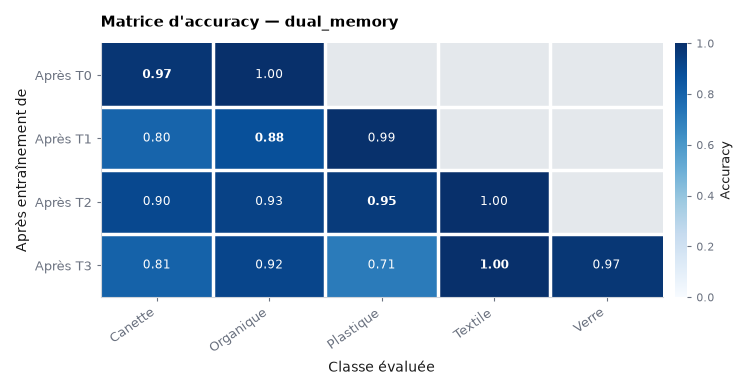

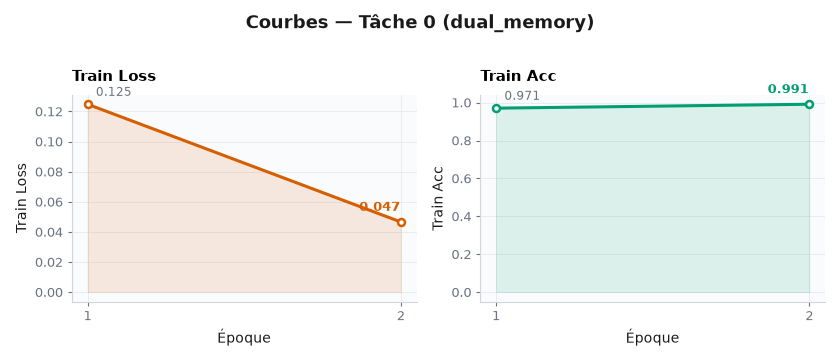

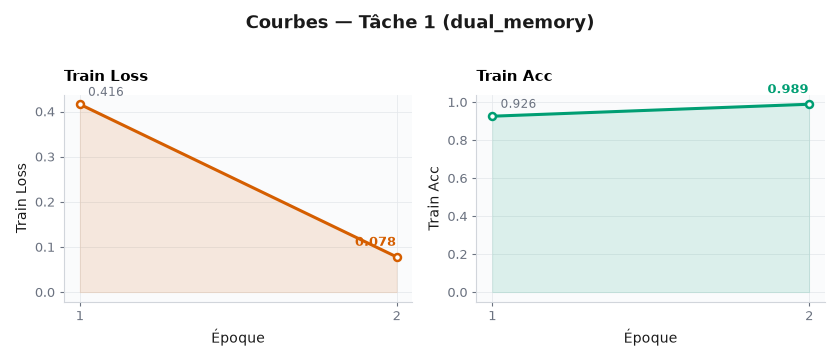

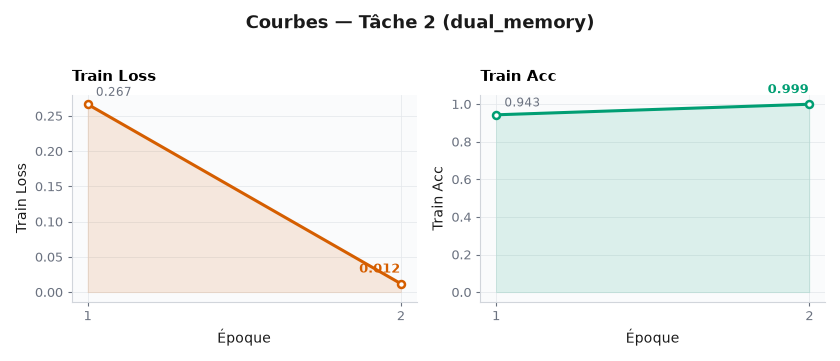

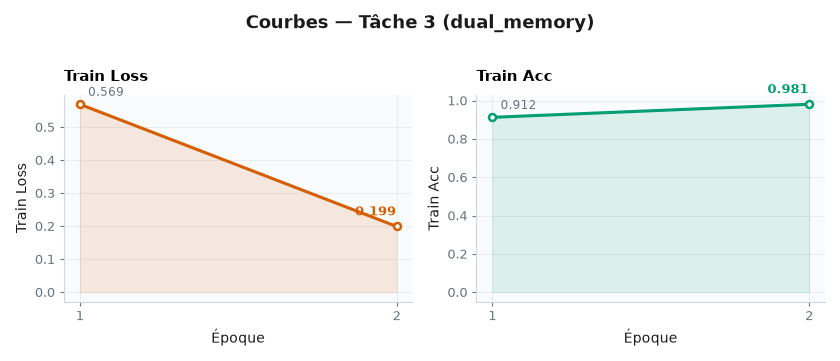

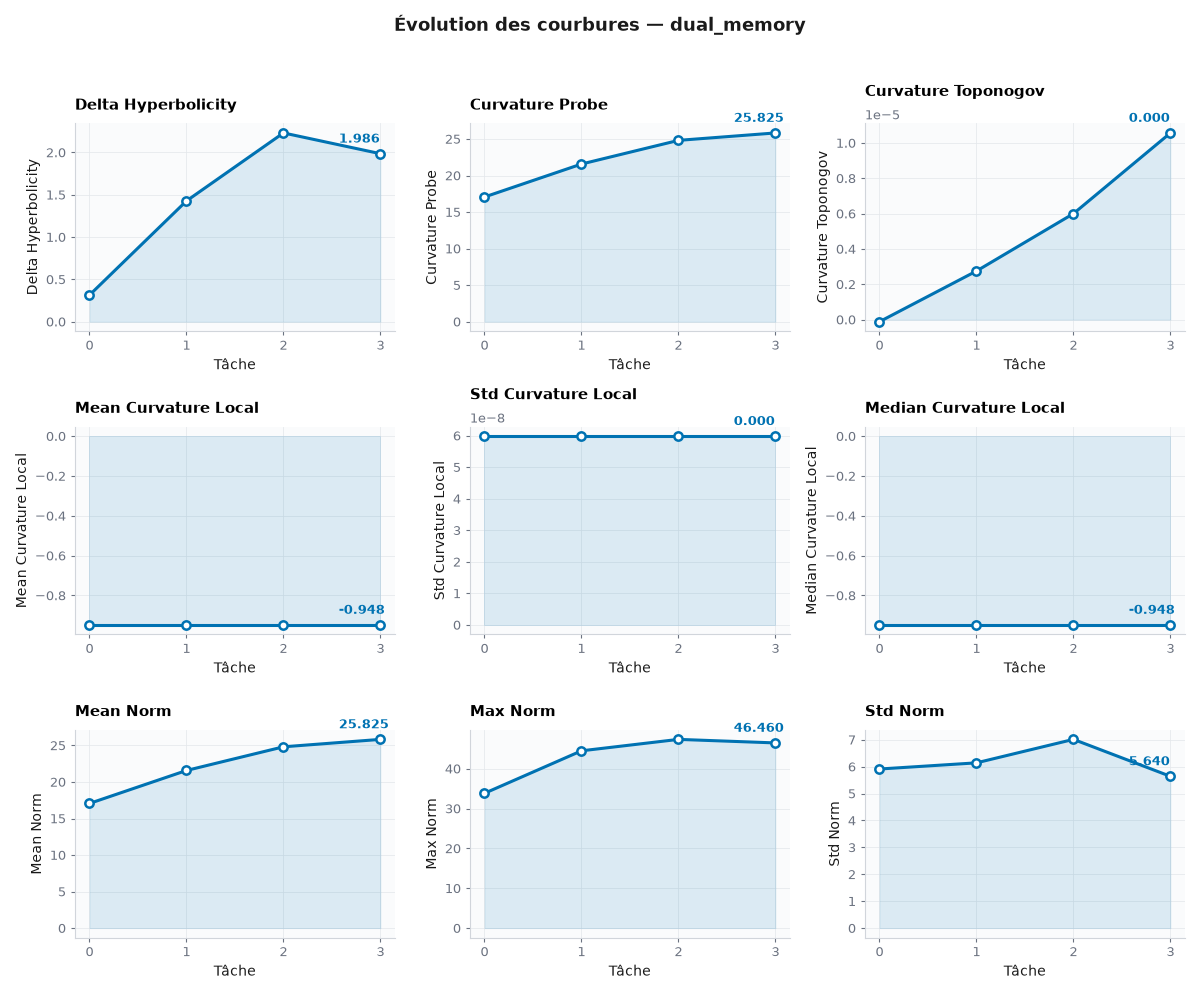

TypeError: 'NoneType' object is not callable

In [26]:


# 1. Matrice d'accuracy
plot_accuracy_matrix(
    acc_matrix,
    class_names=loader.name_label_,
    title=f"Matrice d'accuracy — {STRATEGY}",
    #save_path=f"results/figures/acc_matrix_{STRATEGY}.png",
)

# 2. Courbes d'apprentissage
for entry in history_all:
    plot_learning_curves(
        entry["history"],
        title=f"Courbes — Tâche {entry['task']} ({STRATEGY})",
        #save_path=f"results/figures/curves_{STRATEGY}_task{entry['task']}.png",
    )

# 3. Évolution des courbures
plot_curvature_evolution(
    geometry_history,
    title=f"Évolution des courbures — {STRATEGY}",
    #save_path=f"results/figures/curvature_{STRATEGY}.png",
)

# 4. Heatmap des diagnostics
plot_curvature_heatmap(
    geometry_history,
    title=f"Diagnostics géométriques par tâche — {STRATEGY}",
    #save_path=f"results/figures/geom_heatmap_{STRATEGY}.png",
)

# 5. Résumé
print("\n=== Résumé ===")
#print(summary_table({STRATEGY: acc_matrix},
#                    save_csv=f"results/figures/summary_{STRATEGY}.csv"))


Stratégie : finetune


Using cache found in C:\Users\hp/.cache\torch\hub\facebookresearch_dinov2_main


14:40:01 | INFO    | src.models.backbone | Backbone tronqué : 10 blocs sur 12
14:40:01 | INFO    | src.models.backbone | Backbone gelé


Stream (finetune):   0%|          | 0/4 [00:00<?, ?it/s]


=== Tâche 0 | classes=[0, 1] | strategy=finetune ===


...

[Tâche 3] époques:  50%|█████     | 1/2 [09:12<09:12, 552.75s/it, loss=0.4451, acc=0.926]

21:15:24 | INFO    | src.training.trainer | [Tâche 3] époque 1 | loss=0.1477 | train_acc=0.9850


[Tâche 3] époques: 100%|██████████| 2/2 [18:39<00:00, 559.62s/it, loss=0.1477, acc=0.985]


    accuracy : {0: 0.762, 1: 0.892, 2: 0.652, 3: 1.0, 4: 0.995}


Stream (dual_memory): 100%|██████████| 4/4 [2:46:37<00:00, 2499.37s/it]


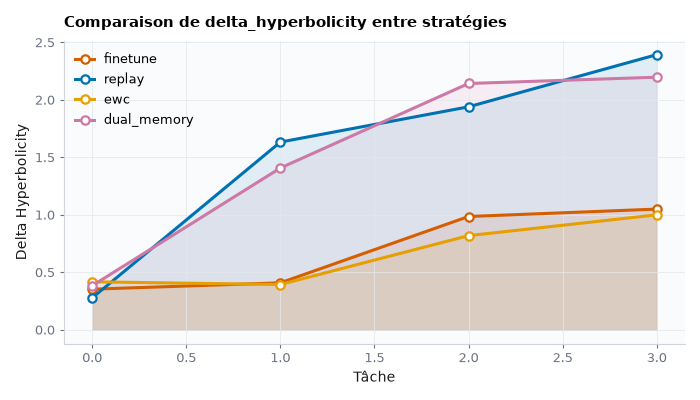

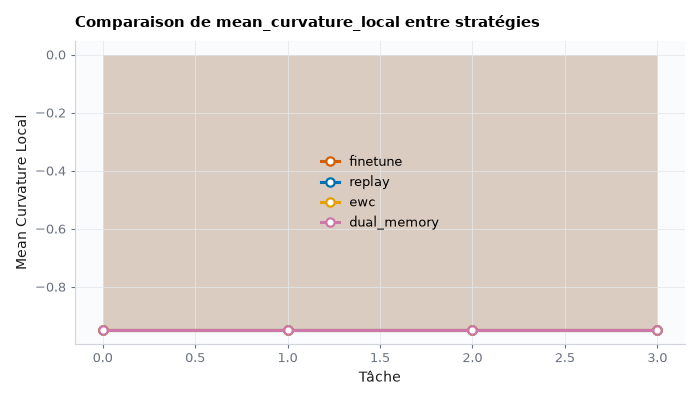

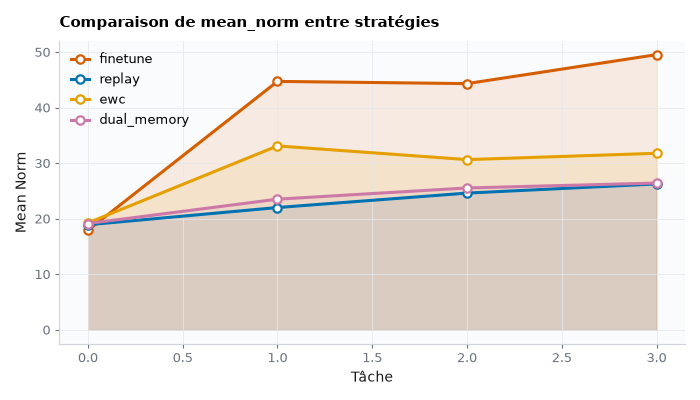

In [27]:
# mccl/notebooks/main.ipynb — cellule 13
# Lancer plusieurs stratégies et comparer leurs courbures
results = {}
geometry_per_strategy = {}

for strat in ["finetune", "replay", "ewc", "dual_memory"]:
    print(f"\n{'='*60}")
    print(f"Stratégie : {strat}")
    print(f"{'='*60}")

    mat, hist, states, geo = run_incremental(strategy_name=strat, n_epochs=2)
    results[strat] = mat
    geometry_per_strategy[strat] = geo

# Comparaison des courbures
for metric in ["delta_hyperbolicity", "mean_curvature_local", "mean_norm"]:
    plot_curvature_comparison(
        geometry_per_strategy,
        metric=metric,
        title=f"Comparaison de {metric} entre stratégies",
        #save_path=f"results/figures/curv_compare_{metric}.png",
    )

In [18]:
# mccl/notebooks/main.ipynb — cellule 11
from src.evaluation.metrics import accuracy

from tqdm import tqdm
@torch.no_grad()
def eval_on_indices(model, indices, n_classes_max=5):
    model.eval()
    ds = LoadDataSubset(images, labels, indices, transform_eval)
    dl = DataLoader(ds, batch_size=32, shuffle=False, num_workers=0)
    all_logits, all_y = [], []
    for xb, yb in tqdm(dl, desc="Évaluation"):
        xb = xb.to(device)
        out = model(xb)
        if out.logits is None:
            continue
        all_logits.append(out.logits.cpu())
        all_y.append(yb)
    if not all_logits:
        return 0.0
    logits = torch.cat(all_logits, 0)
    y_all = torch.cat(all_y, 0)
    return accuracy(logits, y_all)


# Nouveau modèle pour la boucle incrémentale
model_incr = JepaModel(cfg).to(device)

T = len(order) - 1   # tâche 0 = 2 classes, puis 3 tâches
acc_matrix = np.full((T, T), np.nan)

for task in tqdm(stream, desc="Stream"):
    # Enregistrer les nouvelles classes
    model_incr.register_new_classes(task.classes)
    print(f"\n=== Tâche {task.index} | classes={task.classes} ===")

    # Entraîner
    ds_t = LoadDataSubset(images, labels, task.train_idx, transform_train)
    dl_t = DataLoader(ds_t, batch_size=16, shuffle=True, num_workers=0)
    model_incr.train()
    opt = build_optimizer(model_incr, lr=1e-3)
    for epoch in range(2):
        for xb, yb in dl_t:
            xb, yb = xb.to(device), yb.to(device)
            out = model_incr(xb)
            loss = classification_loss(out.logits, yb)
            opt.zero_grad(); loss.backward(); opt.step()

    # Évaluer sur les classes vues
    acc = eval_on_indices(model_incr, task.test_idx)
    print(f"Accuracy sur classes vues : {acc:.4f}")
    acc_matrix[task.index, :len(task.seen_classes)] = acc

print("\nMatrice d'accuracy :")
print(np.round(acc_matrix, 3))

Using cache found in C:\Users\hp/.cache\torch\hub\facebookresearch_dinov2_main


14:47:51 | INFO    | src.models.backbone | Backbone tronqué : 10 blocs sur 12
14:47:51 | INFO    | src.models.backbone | Backbone gelé


Stream:   0%|          | 0/4 [00:00<?, ?it/s]


=== Tâche 0 | classes=[0, 1] ===


Stream:  25%|██▌       | 1/4 [09:58<29:54, 598.20s/it]

...

Accuracy sur classes vues : 0.3845

=== Tâche 2 | classes=[3] ===


Stream:  75%|███████▌  | 3/4 [25:31<08:16, 496.86s/it]

Accuracy sur classes vues : 0.2834

=== Tâche 3 | classes=[4] ===


Stream: 100%|██████████| 4/4 [34:21<00:00, 515.38s/it]


Accuracy sur classes vues : 0.2268

Matrice d'accuracy :
[[0.992 0.992   nan   nan]
 [0.385 0.385 0.385   nan]
 [0.283 0.283 0.283 0.283]
 [0.227 0.227 0.227 0.227]]


In [13]:
for task in stream:
    print(f"Tâche {task.index} : classes={task.classes}")
    print(f"  labels uniques dans train_idx : {np.unique(labels[task.train_idx])}")

Tâche 0 : classes=[0, 1]
  labels uniques dans train_idx : [0 1]
Tâche 1 : classes=[2]
  labels uniques dans train_idx : [2]
Tâche 2 : classes=[3]
  labels uniques dans train_idx : [3]
Tâche 3 : classes=[4]
  labels uniques dans train_idx : [4]


In [14]:
# Rejouer la boucle mais afficher l'état du classifieur
for task in stream:
    model_incr.register_new_classes(task.classes)
    print(f"Tâche {task.index} : class_ids={model_incr.classifier.class_ids()}")

Tâche 0 : class_ids=[0, 1, 2, 3, 4]
Tâche 1 : class_ids=[0, 1, 2, 3, 4]
Tâche 2 : class_ids=[0, 1, 2, 3, 4]
Tâche 3 : class_ids=[0, 1, 2, 3, 4]


In [22]:
# 1. Test direct de TaskStream
for task in stream:
    print(f"task {task.index}: classes={task.classes}")

# 2. Vérifier l'identité des modèles
print("model is model_incr :", model is model_incr)
print("model.classifier.class_ids()     :", model.classifier.class_ids())
print("model_incr.classifier.class_ids():", model_incr.classifier.class_ids())

task 0: classes=[0, 1]
task 1: classes=[2]
task 2: classes=[3]
task 3: classes=[4]
model is model_incr : False
model.classifier.class_ids()     : [0, 1]
model_incr.classifier.class_ids(): [0, 1, 2, 3, 4]


In [5]:
from tqdm.notebook import tqdm
import time

for i in tqdm(range(20), desc="Test"):
    time.sleep(0.1)

Test:   0%|          | 0/20 [00:00<?, ?it/s]

In [23]:
model_incr = JepaModel(cfg).to(device)

Using cache found in C:\Users\hp/.cache\torch\hub\facebookresearch_dinov2_main


00:06:53 | INFO    | src.models.backbone | Backbone tronqué : 10 blocs sur 12
00:06:53 | INFO    | src.models.backbone | Backbone gelé


In [24]:
print("class_ids avant la boucle :", model_incr.classifier.class_ids())

class_ids avant la boucle : []


## 9. Diagnostics géométriques

Mesure de la δ-hyperbolicité et de la distorsion sur les embeddings globaux.

In [19]:
# mccl/notebooks/main.ipynb — cellule 12
@torch.no_grad()
def extract_global_embeddings(model, indices, n_max=512):
    model.eval()
    ds = LoadDataSubset(images, labels, indices[:n_max], transform_eval)
    dl = DataLoader(ds, batch_size=32, shuffle=False, num_workers=0)
    feats = []
    for xb, _ in dl:
        xb = xb.to(device)
        out = model(xb)
        feats.append(out.global_embed.cpu())
    return torch.cat(feats, 0)


emb = extract_global_embeddings(model_incr, te)
print("Embeddings :", emb.shape)

# Diagnostics
print("Norme moyenne des embeddings :", float(torch.linalg.vector_norm(emb, dim=-1).mean()))
print("δ-hyperbolicité              :", delta_hyperbolicity(emb[:256], n_quadruples=128))
print("Distorsion (E → manifold)    :", distortion(emb[:256], emb[:256]))

Embeddings : torch.Size([512, 192])
Norme moyenne des embeddings : 40.69035720825195
δ-hyperbolicité              : 2.4671947956085205
Distorsion (E → manifold)    : 1.0


## 10. Sauvegarde des résultats

In [22]:
# mccl/notebooks/main.ipynb — cellule 13
import json
from src.utils.checkpoint import save_json

results = {
    "order": order,
    "acc_matrix": acc_matrix.tolist(),
    "avg_acc": float(np.nanmean(acc_matrix[-1])),
    "class_mapping": loader.class_mapping_,
}

out_path = ROOT / "results" / "main_run.json"
out_path.parent.mkdir(parents=True, exist_ok=True)
save_json(str(out_path), results)
print("Résultats sauvegardés :", out_path)

Résultats sauvegardés : c:\Users\hp\Documents\mccl\results\main_run.json


## Récapitulatif

| Section | Ce qui est fait |
|---|---|
| 1 | Environnement, seeds, imports |
| 2 | Chargement du zip + réparation des attributs |
| 3 | Encodage labels + split 70/15/15 |
| 4 | DataLoaders PyTorch + visualisation |
| 5 | Vérification géométrique des manifolds |
| 6 | Smoke test d'entraînement sur 2 classes |
| 7 | TaskStream incrémental |
| 8 | Boucle complète : entraînement + évaluation + matrice d'accuracy |
| 9 | Diagnostics géométriques |
| 10 | Sauvegarde JSON des résultats |

**Prochaines étapes :**
- Remplacer le placeholder `images` par de vraies images (déjà fait si `Load_data` est correct)
- Ajouter la mémoire duale (`continual/memory.py`)
- Brancher la surprise et la consolidation
- Activer la prédiction JEPA masquée avec `random_block_mask`
- Évaluer l'OOD avec `evaluation/ood_metrics.py`